# Clio-Infra without the server — the clients beneath the tools

`mcp.ipynb` reaches Clio over SSE. The tools it calls are thin wrappers around
two Python classes, and this notebook uses those classes directly: same
database, same rows, no server process.

Clio has no per-request API, so it has no vendor client — `utils/fetch.py`
downloads the workbooks once. What serves it is the same pair that serves
WONDER, NVSR and Voteview:

| class | table | answers |
| --- | --- | --- |
| `SeriesCatalogClient` | `series_catalog` | which series exist — searchable by facet |
| `TimeSeriesSourceClient` | `time_series_source` | a series' coverage and its observations, by id |

Nothing about either is Clio-specific; `source="clio"` is a column value.

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
sys.path.append("../")
sys.path.append("../../")

import numpy
from matplotlib import pyplot

from lib import config
from mcp_server.series_catalog import SeriesCatalogClient
from mcp_server.timeseries_source import TimeSeriesSourceClient, TimeSeriesSourceError
from utils import break_gaps, stamp_source

pyplot.style.use(config.glyfish_style)

## What exists

The catalog is where every lookup starts. Each Clio indicator is a *concept*,
with one series per country.

In [2]:
async with SeriesCatalogClient() as catalog:
    concepts = await catalog.concepts(source="clio")

print(f"{len(concepts)} indicators, {sum(c['series_count'] for c in concepts):,} country series")
for c in sorted(concepts, key=lambda c: -c["series_count"])[:5]:
    print(f"  {c['series_count']:4d}  {c['concept']}")

86 indicators, 11,042 country series
   193  composite_measure_of_wellbeing
   191  armed_conflicts_internal
   191  armed_conflicts_international
   190  total_population
   186  unified_democracy_scores_uds


## Finding series by facet

Facets are `indicator`, `country`, `category`, `ccode` and `kind`. The last is
the one to know about: a **measured** series was observed, a **panel** is filled
for every country (Armed Conflicts is 0/1 since 1500), and a **reconstruction**
is a model's estimate at benchmark years. Coverage counts all three alike, so
filter on `kind` when it matters whether anyone measured it.

In [3]:
async with SeriesCatalogClient() as catalog:
    for kind in ("measured", "panel", "reconstruction"):
        _, total = await catalog.search(source="clio", facets={"kind": kind}, limit=1)
        print(f"  {kind:15s} {total:6,d} series")

    us, total = await catalog.search(source="clio", limit=200,
                                     facets={"country": "united_states", "kind": "measured"})

print(f"\n{total} measured indicators for the United States; the five that start earliest:")
for e in sorted(us, key=lambda e: e.observation_start)[:5]:
    print(f"  {str(e.observation_start)[:4]}  {e.concept:40s} {e.units or '(no unit)'}")

  measured         6,275 series
  panel            2,523 series
  reconstruction   2,244 series

47 measured indicators for the United States; the five that start earliest:
  1500  exchange_rates_to_us_dollar              Exchange Rates to 1 Unit of Currency of the US
  1500  total_population                         in thousands
  1600  total_urban_population                   in thousands
  1600  urbanization_ratio                       urban population as a percentage of total population
  1650  gdp_per_capita                           in 1990 international Geary-Khamis dollars


`kind` belongs to the indicator, not to each value. Population and urbanisation
count as measured, but before 1800 their values are estimates on a fifty-year
grid — which is how the United States has a "measured" population for 1500. For
the early centuries, read the source rather than the facet.


## Coverage by id

The catalog hands back ids; `describe` turns them into coverage and staleness
without fetching a single observation. It takes ids and nothing else — there
is no call that lists the table.

In [4]:
ids = [f"clio/life_expectancy_at_birth_total/{c}"
       for c in ("united_kingdom", "sweden", "united_states", "india", "atlantis")]
async with TimeSeriesSourceClient() as store:
    refs = await store.describe(ids)

found = {r.native_id for r in refs}
for r in refs:
    print(f"  {r.native_id:48s} {r.observation_count:3d} obs  "
          f"{r.observation_start.year}-{r.observation_end.year}  stale={r.stale}")
print(f"  not stored: {[i for i in ids if i not in found]}")

  clio/life_expectancy_at_birth_total/india         71 obs  1881-2009  stale=False
  clio/life_expectancy_at_birth_total/sweden       261 obs  1751-2011  stale=False
  clio/life_expectancy_at_birth_total/united_kingdom 230 obs  1543-2011  stale=False
  clio/life_expectancy_at_birth_total/united_states 113 obs  1880-2011  stale=False
  not stored: ['clio/life_expectancy_at_birth_total/atlantis']


## One series in full

Values are strings, as the storage contract keeps them. The unit is not from
the main-site workbook — which states none — but from the DataverseNL deposit
filed under `notebooks/clio_historical`; the metadata says where the series
came from and what kind of row it is.

In [5]:
async with TimeSeriesSourceClient() as store:
    uk = await store.get_series("clio", "clio/life_expectancy_at_birth_total/united_kingdom")

meta = uk.metadata["clio"]
print(uk.title)
print(f"  {uk.units} | {uk.frequency} | {uk.observation_count} obs "
      f"{uk.observation_start}..{uk.observation_end} | stale={uk.stale}")
print(f"  kind {meta['kind'][0]} | category {meta['category'][0]} | handle {meta['handle'][0]}")
print(f"  definition: {meta['definition'][0]}")
print(f"  first: {uk.observations[0]!r}")

Life Expectancy at Birth (Total) — United Kingdom


  years | Annual | 230 obs 1543-01-01..2011-01-01 | stale=False
  kind measured | category Demography | handle 10622/LKYT53
  definition: Period Life Expectancy at birth for the total population
  first: Observation(date='1543-01-01', value='33.94')


## A miss is loud

In [6]:
async with TimeSeriesSourceClient() as store:
    try:
        await store.get_series("clio", "clio/life_expectancy_at_birth_total/atlantis")
    except TimeSeriesSourceError as error:
        print(f"{type(error).__name__}: {error}")

TimeSeriesSourceError: no series clio:clio/life_expectancy_at_birth_total/atlantis


## Four centuries of life expectancy

Straight from the store. The lines break at each country's gaps rather than
bridging them, and the dots are observations with a gap on both sides — without
them the United Kingdom's first three centuries, 1543 to 1840, would not show at
all, because a lone point between two holes has no line to draw.

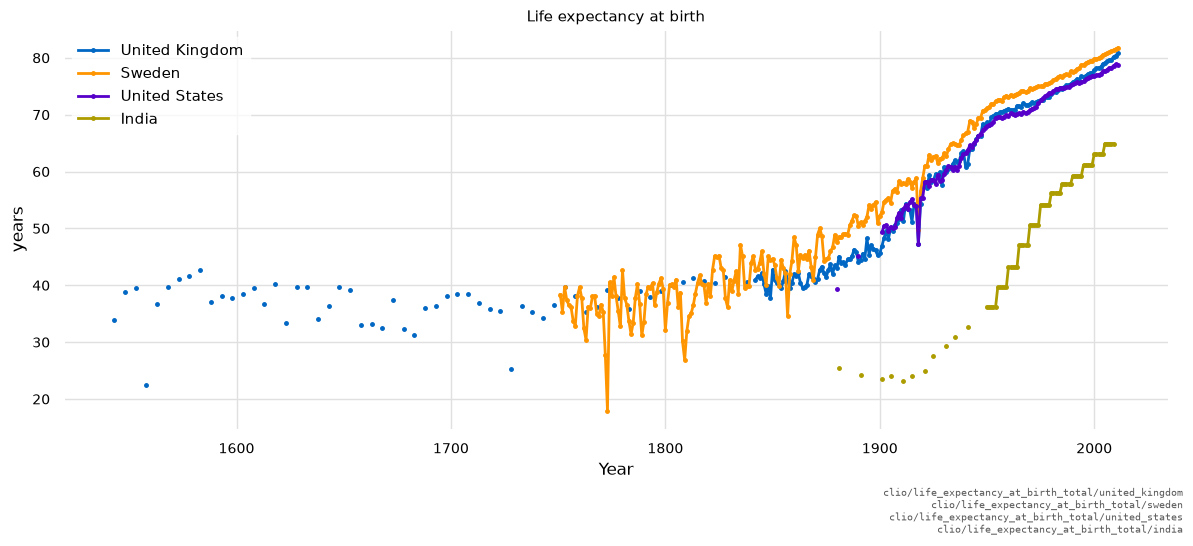

In [7]:
countries = ("united_kingdom", "sweden", "united_states", "india")
async with TimeSeriesSourceClient() as store:
    series = [await store.get_series("clio", f"clio/life_expectancy_at_birth_total/{c}")
              for c in countries]

figure, axis = pyplot.subplots(figsize=(12, 5.5))
for s in series:
    years = [int(o.date[:4]) for o in s.observations]
    values = [float(o.value) for o in s.observations]
    grid, filled = break_gaps(numpy.array(years), numpy.array(values))
    # markers: a lone observation between two gaps has no line to draw
    axis.plot(grid, filled, lw=2, marker="o", markersize=2.5,
              label=s.metadata["clio"]["country"][0])
axis.set_ylabel(series[0].units)
axis.set_xlabel("Year")
axis.set_title("Life expectancy at birth", fontsize=11)
axis.legend(loc="upper left")
figure.tight_layout()
stamp_source(*[{"native_id": s.native_id} for s in series], figure=figure)

Two things the chart shows that the data is responsible for. India after 1950
is a staircase because its values are **five-year averages repeated for each
year** — 36.185 for every year 1950–54, 39.63 for 1955–59 — so its "annual"
series is really quinquennial, and four year-on-year changes in five are zero.
And the dips are real: Sweden's 1773 famine, England's influenza of 1557–59.

For the same flow over the wire — the tools a model would call, in the order it
would call them — see [`mcp.ipynb`](mcp.ipynb).